In [2]:
print("CELL 1: setup, publication style, helpers")
import os, json, glob, shutil
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = "/content/drive/MyDrive/fedllm-safety-defense"
RES = f"{PROJECT_ROOT}/results"
V8 = f"{RES}/part4c_diagnostic/v8-clean"
FS = f"{RES}/part4c_diagnostic/forced_state"
E2E = f"{RES}/part4c_diagnostic/end_to_end"
UTIL = f"{RES}/part4c_diagnostic/utility_v2"
FIG_DIR = f"{RES}/figures"; os.makedirs(FIG_DIR, exist_ok=True)
SEEDS3, SEEDS6 = [42, 43, 44], [42, 43, 44, 45, 46, 47]

# Okabe-Ito colour-blind-safe palette
C = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
     "purple": "#CC79A7", "sky": "#56B4E9", "grey": "#7F7F7F", "black": "#000000"}
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.2, "lines.markersize": 3.5,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.4,
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42, "ps.fonttype": 42,          # embed TrueType fonts (journal requirement)
})
COL1, COL2 = 3.4, 7.0      # single- and double-column widths in inches; adjust to your template

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIG_DIR}/{name}.{ext}")
    plt.close(fig)
    print(f"  saved {FIG_DIR}/{name}.pdf (+ .png)")

def panel(ax, s):
    ax.text(-0.13, 1.04, s, transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")

def load_json(path):
    assert os.path.exists(path), f"missing input file: {path}"
    return json.load(open(path))

def auc_np(neg, pos):                 # P(pos is more suspicious than neg), ties count half
    d = pos[:, None] - neg[None, :]
    return float((d > 0).mean() + 0.5 * (d == 0).mean())

def auc_ci(neg, pos, sign, n_boot=2000, seed=0):
    """AUC with a stratified bootstrap 95% CI. sign=-1: more negative score = more suspicious; sign=+1: larger = more suspicious."""
    neg, pos = sign * np.asarray(neg, float), sign * np.asarray(pos, float)
    rng = np.random.default_rng(seed)
    boots = [auc_np(rng.choice(neg, len(neg)), rng.choice(pos, len(pos))) for _ in range(n_boot)]
    return auc_np(neg, pos), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

def errbar(ax, x, a, **kw):           # a: array of (auc, lo, hi)
    a = np.asarray(a)
    ax.errorbar(x, a[:, 0], yerr=[a[:, 0] - a[:, 1], a[:, 2] - a[:, 0]], capsize=1.5, elinewidth=0.7, **kw)
print("ready; figures will be written to", FIG_DIR)

CELL 1: setup, publication style, helpers
Mounted at /content/drive
ready; figures will be written to /content/drive/MyDrive/fedllm-safety-defense/results/figures


In [4]:
print("CELL 1b: input check (run before the figure cells; confirms every file exists and has the structure the plots expect)")
checks = {
    "v8-clean example": f"{V8}/fedavg_frac0.4_seed42_final.json",
    "signal_comparison.json": f"{FS}/signal_comparison.json",
    "reference_scoring.json": f"{FS}/reference_scoring.json",
    "descriptors.pt": f"{FS}/descriptors.pt",
    "Part 0 direction (.pt)": f"{RES}/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt",
    "end_to_end example": f"{E2E}/refdrop1_matched_frac0.4_seed47_final.json",
    "utility example": f"{UTIL}/refdrop1_plain_frac0.0_seed42_final.json",
}
J = {}
for name, p in checks.items():
    ok = os.path.exists(p)
    if ok and p.endswith(".json"): J[name] = json.load(open(p))
    print(f"  {'OK     ' if ok else 'MISSING'} {name}" + (f" | top-level keys: {list(J[name])[:7]}" if name in J else ""))
if "v8-clean example" in J:     print("  v8 trajectory entry:", J["v8-clean example"]["trajectory"][1])
if "signal_comparison.json" in J:
    k0 = next(iter(J["signal_comparison.json"])); print("  signal_comparison[k] groups:", list(J["signal_comparison.json"][k0]), "| signals:", list(J["signal_comparison.json"][k0]["benign"]))
if "reference_scoring.json" in J:
    k0 = next(iter(J["reference_scoring.json"])); print("  reference_scoring[k] groups:", list(J["reference_scoring.json"][k0]), "| keys:", list(J["reference_scoring.json"][k0]["benign"]))
if "end_to_end example" in J:   print("  end_to_end log keys:", list(J["end_to_end example"]["log"][0]), "| traj length:", len(J["end_to_end example"]["traj"]))
if "utility example" in J:      print("  utility keys:", [k for k in J["utility example"] if k in ("traj", "util")], "| util length:", len(J["utility example"]["util"]))
try:
    import torch
    D = torch.load(checks["descriptors.pt"], weights_only=False); r0 = D["rows"][0]
    print("  descriptors row keys:", list(r0), "| shift layers:", list(r0["shift"]),
          "| groups:", sorted({r["group"] for r in D["rows"]}), "| splits:", sorted({r["split"] for r in D["rows"]}))
except Exception as e:
    print("  could not inspect descriptors.pt:", repr(e)[:200])

CELL 1b: input check (run before the figure cells; confirms every file exists and has the structure the plots expect)
  OK      v8-clean example | top-level keys: ['method', 'malicious_fraction', 'seed', 'malicious_ids', 'trajectory', 'log']
  OK      signal_comparison.json | top-level keys: ['0', '3', '6', '9']
  OK      reference_scoring.json | top-level keys: ['3', '6', '9']
  OK      descriptors.pt
  OK      Part 0 direction (.pt)
  OK      end_to_end example | top-level keys: ['defense', 'attack', 'frac', 'seed', 'malicious_ids', 'traj', 'log']
  OK      utility example | top-level keys: ['defense', 'frac', 'seed', 'malicious_ids', 'traj', 'util', 'log']
  v8 trajectory entry: {'round': 1, 'refusal_rate': 0.90625}
  signal_comparison[k] groups: ['benign', 'malicious'] | signals: ['proj', 'refmass', 'norm']
  reference_scoring[k] groups: ['benign', 'malicious', 'malicious_matched', 'narrow'] | keys: ['std', 'ref']
  end_to_end log keys: ['round', 'sampled', 'malicious', 'scores', '

In [3]:
print("CELL 1c: reconcile the files the figures read against the numbers already reported in the analysis")
def fmt0(v): return f"{v:.0f}"
def auc_pt(neg, pos, sign): return auc_np(sign * np.asarray(neg, float), sign * np.asarray(pos, float))
results = []
def check(name, got, want, tol=None, as_int=False):
    try:
        if as_int: ok = [fmt0(g) for g in got] == [str(w) for w in want]; shown = [fmt0(g) for g in got]
        else:      ok = all(abs(g - w) <= tol for g, w in zip(got, want)) and len(got) == len(want); shown = [round(g, 3) for g in got]
    except Exception as e:
        ok, shown = False, f"ERROR {repr(e)[:80]}"
    results.append(ok); print(f"  {'MATCH   ' if ok else 'MISMATCH'} {name}: file -> {shown} | reported -> {want}")

print("\nA. v8-clean (Figure 1): final refusal %, seeds 42/43/44")
for f, want in {0.0: [62.5, 65.6, 65.6], 0.2: [59.4, 25.0, 65.6], 0.4: [15.6, 3.1, 9.4]}.items():
    check(f"{int(f * 100)}% malicious", [load_json(f"{V8}/fedavg_frac{f}_seed{s}_final.json")["trajectory"][-1]["refusal_rate"] * 100 for s in SEEDS3], want, tol=0.06)

print("\nB. signal_comparison.json (Figure 2): AUC at k=0/3/6/9")
sc_ = load_json(f"{FS}/signal_comparison.json")
for key, sign, want in [("proj", -1, [1.0, 0.79, 0.62, 0.49]), ("refmass", -1, [1.0, 0.70, 0.55, 0.31]), ("norm", +1, [1.0, 0.97, 1.0, 1.0])]:
    check(f"{key} benign vs malicious", [auc_pt(sc_[str(k)]["benign"][key], sc_[str(k)]["malicious"][key], sign) for k in (0, 3, 6, 9)], want, tol=0.0015)

print("\nC. reference_scoring.json (Figure 4): AUC standard -> reference at k=3/6/9")
rs_ = load_json(f"{FS}/reference_scoring.json")
for title, neg, pos, std, ref in [("benign vs malicious", "benign", "malicious", [0.67, 0.78, 0.51], [0.91, 0.95, 0.84]),
                                  ("benign vs norm-matched", "benign", "malicious_matched", [0.53, 0.54, 0.31], [0.65, 0.77, 0.66]),
                                  ("narrow-benign vs malicious", "narrow", "malicious", [0.94, 0.93, 0.54], [1.00, 1.00, 0.86]),
                                  ("benign vs narrow-benign", "benign", "narrow", [0.13, 0.15, 0.46], [0.10, 0.11, 0.33])]:
    check(f"{title} (standard)", [auc_pt(rs_[str(k)][neg]["std"], rs_[str(k)][pos]["std"], -1) for k in (3, 6, 9)], std, tol=0.006)
    check(f"{title} (reference)", [auc_pt(rs_[str(k)][neg]["ref"], rs_[str(k)][pos]["ref"], -1) for k in (3, 6, 9)], ref, tol=0.006)

print("\nD. descriptors.pt validation rows (Figure 3): AUC at k=0/3/6/9")
import torch
Dd = torch.load(f"{FS}/descriptors.pt", weights_only=False)
d0_ = torch.load(f"{RES}/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt", weights_only=False).float().cpu()
rows_ = [{"k": r["k"], "split": r["split"], "group": r["group"], "norm": float(r["norm"]), "proj": float(r["shift"][14].float().cpu() @ d0_)} for r in Dd["rows"]]
def g_(k, group, key): return [r[key] for r in rows_ if (r["split"], r["k"], r["group"]) == ("validation", k, group)]
for key, sign, tag, table in [("proj", -1, "projection", [("benign vs malicious", "benign", "malicious", [1.00, 0.97, 0.77, 0.26]), ("vs norm-matched", "benign", "malicious_matched", [1.00, 0.94, 0.59, 0.09]),
                                                         ("narrow vs malicious", "narrow", "malicious", [1.00, 1.00, 0.82, 0.41]), ("benign vs narrow", "benign", "narrow", [0.40, 0.33, 0.25, 0.25])]),
                              ("norm", +1, "weight norm", [("benign vs malicious", "benign", "malicious", [1.00, 0.98, 1.00, 1.00]), ("vs norm-matched", "benign", "malicious_matched", [0.77, 0.24, 0.24, 0.24]),
                                                           ("narrow vs malicious", "narrow", "malicious", [1.00, 0.89, 0.99, 1.00]), ("benign vs narrow", "benign", "narrow", [0.99, 0.86, 0.84, 0.81])])]:
    for title, neg, pos, want in table:
        check(f"{tag}: {title}", [auc_pt(g_(k, neg, key), g_(k, pos, key), sign) for k in (0, 3, 6, 9)], want, tol=0.0015)

print("\nE. end_to_end (Figures 5-8): final refusal %, seeds in order")
def fin(d, a, f, seeds): return [load_json(f"{E2E}/{d}_{a}_frac{f}_seed{s}_final.json")["traj"][-1] * 100 for s in seeds]
for d, a, f, seeds, want in [("fedavg", "plain", 0.4, SEEDS3, [25, 3, 12]), ("refdrop1", "plain", 0.4, SEEDS3, [56, 44, 56]), ("normdrop1", "plain", 0.4, SEEDS3, [66, 41, 66]),
                             ("fedavg", "matched", 0.4, SEEDS6, [47, 9, 41, 41, 6, 3]), ("refdrop1", "matched", 0.4, SEEDS6, [50, 50, 62, 69, 6, 6]),
                             ("normdrop1", "matched", 0.4, SEEDS6, [47, 38, 25, 66, 19, 0]), ("median", "matched", 0.4, SEEDS3, [28, 0, 19]),
                             ("normclip", "matched", 0.4, SEEDS3, [50, 9, 41]), ("refdrop1", "plain", 0.0, SEEDS3, [72, 69, 72]), ("fedavg", "plain", 0.0, SEEDS3, [66, 66, 66])]:
    check(f"{d} / {a} / {int(f * 100)}% malicious", fin(d, a, f, seeds), want, as_int=True)

print("\nF. utility_v2 (Figure 8): held-out loss after round 10 (round 0 = 1.850)")
for d, want in [("fedavg", [1.718, 1.718, 1.717]), ("refdrop1", [1.728, 1.721, 1.721])]:
    check(f"{d}, 0% malicious", [load_json(f"{UTIL}/{d}_plain_frac0.0_seed{s}_final.json")["util"][-1] for s in SEEDS3], want, tol=0.0006)

print(f"\nSUMMARY: {sum(results)} of {len(results)} checks match the numbers reported in the analysis.")
print("Folders under part4c_diagnostic (the figure code reads only v8-clean, forced_state, end_to_end, utility_v2):")
for d in sorted(glob.glob(f"{RES}/part4c_diagnostic/*")):
    print(f"  {os.path.basename(d):34s} {'folder, ' + str(len(os.listdir(d))) + ' items' if os.path.isdir(d) else 'file'}")

CELL 1c: reconcile the files the figures read against the numbers already reported in the analysis

A. v8-clean (Figure 1): final refusal %, seeds 42/43/44
  MATCH    0% malicious: file -> [62.5, 65.625, 65.625] | reported -> [62.5, 65.6, 65.6]
  MATCH    20% malicious: file -> [59.375, 25.0, 65.625] | reported -> [59.4, 25.0, 65.6]
  MATCH    40% malicious: file -> [15.625, 3.125, 9.375] | reported -> [15.6, 3.1, 9.4]

B. signal_comparison.json (Figure 2): AUC at k=0/3/6/9
  MATCH    proj benign vs malicious: file -> [1.0, 0.79, 0.62, 0.49] | reported -> [1.0, 0.79, 0.62, 0.49]
  MATCH    refmass benign vs malicious: file -> [1.0, 0.7, 0.55, 0.31] | reported -> [1.0, 0.7, 0.55, 0.31]
  MATCH    norm benign vs malicious: file -> [1.0, 0.97, 1.0, 1.0] | reported -> [1.0, 0.97, 1.0, 1.0]

C. reference_scoring.json (Figure 4): AUC standard -> reference at k=3/6/9
  MATCH    benign vs malicious (standard): file -> [0.67, 0.78, 0.51] | reported -> [0.67, 0.78, 0.51]
  MATCH    benign vs mal

In [5]:
print("CELL 2: Figure 1 -- the attack under true FedAvg (no defense)")
def v8_traj(frac, seed):
    return np.array([t["refusal_rate"] * 100 for t in load_json(f"{V8}/fedavg_frac{frac}_seed{seed}_final.json")["trajectory"]])
fracs, cols = [0.0, 0.2, 0.4], [C["blue"], C["orange"], C["red"]]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.4), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
for f, c in zip(fracs, cols):
    T = np.stack([v8_traj(f, s) for s in SEEDS3]); x = np.arange(T.shape[1])
    ax.fill_between(x, T.min(0), T.max(0), color=c, alpha=0.18, lw=0)
    ax.plot(x, T.mean(0), color=c, label=f"{int(f * 100)}% malicious")
ax.axhline(20, color=C["grey"], ls="--", lw=0.7)
ax.text(0.2, 21.5, "collapse threshold (20%)", fontsize=6, color=C["grey"])
ax.set_xlabel("Federated round"); ax.set_ylabel("Refusal rate (%)"); ax.set_ylim(0, 100); ax.set_xlim(0, 10)
ax.legend(frameon=False, loc="upper right"); panel(ax, "(a)")
ax = axes[1]
for i, (f, c) in enumerate(zip(fracs, cols)):
    finals = [v8_traj(f, s)[-1] for s in SEEDS3]
    ax.bar(i, np.mean(finals), color=c, alpha=0.35, width=0.62, lw=0)
    ax.scatter(i + np.linspace(-0.13, 0.13, len(finals)), finals, color=c, s=14, zorder=3, edgecolor="white", linewidth=0.4)
ax.set_xticks(range(3)); ax.set_xticklabels(["0%", "20%", "40%"]); ax.grid(axis="x", visible=False)
ax.set_xlabel("Malicious fraction"); ax.set_ylabel("Final refusal (%)"); ax.set_ylim(0, 100); panel(ax, "(b)")
fig.tight_layout(); save(fig, "fig1_attack_true_fedavg")

CELL 2: Figure 1 -- the attack under true FedAvg (no defense)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig1_attack_true_fedavg.pdf (+ .png)


In [6]:
print("CELL 3: Figure 2 -- the detection window (AUC vs benign rounds) and why it closes")
sc = load_json(f"{FS}/signal_comparison.json")
KS = sorted(int(k) for k in sc)
SIG = [("proj", "Projection shift (layer 14)", -1, C["blue"], "o", -0.15),
       ("refmass", "Refusal-token log-mass", -1, C["orange"], "s", 0.0),
       ("norm", "Weight-update norm", +1, C["green"], "^", 0.15)]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.5))
ax = axes[0]
for key, name, sign, c, m, off in SIG:
    a = [auc_ci(sc[str(k)]["benign"][key], sc[str(k)]["malicious"][key], sign) for k in KS]
    errbar(ax, np.array(KS) + off, a, color=c, marker=m, label=name)
ax.axhline(0.5, color=C["grey"], ls="--", lw=0.7); ax.text(KS[0] - 0.3, 0.47, "chance", fontsize=6, color=C["grey"], ha="left", va="top")
ax.set_xlabel("Benign-only rounds before scoring ($k$)"); ax.set_ylabel("AUC (malicious vs. benign)")
ax.set_xticks(KS); ax.set_ylim(0, 1.05); ax.legend(frameon=False, loc="lower left"); panel(ax, "(a)")
ax = axes[1]
for grp, c in [("benign", C["blue"]), ("malicious", C["red"])]:
    m = np.array([np.mean(sc[str(k)][grp]["proj"]) for k in KS]); s = np.array([np.std(sc[str(k)][grp]["proj"]) for k in KS])
    ax.plot(KS, m, color=c, marker="o", label=grp); ax.fill_between(KS, m - s, m + s, color=c, alpha=0.18, lw=0)
ax.set_xlabel("Benign-only rounds before scoring ($k$)"); ax.set_ylabel("Projection shift (mean $\\pm$ s.d.)")
ax.set_xticks(KS); ax.legend(frameon=False, loc="lower right"); panel(ax, "(b)")
fig.tight_layout(); save(fig, "fig2_detection_window")

CELL 3: Figure 2 -- the detection window (AUC vs benign rounds) and why it closes
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig2_detection_window.pdf (+ .png)


In [7]:
print("CELL 4: Figure 3 -- held-out validation: norm-matched attacker and narrow-benign false-positive check")
def load_descriptors():
    import torch
    D = torch.load(f"{FS}/descriptors.pt", weights_only=False)
    d0 = torch.load(f"{RES}/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt", weights_only=False).float().cpu()
    return [{"k": r["k"], "split": r["split"], "group": r["group"], "norm": float(r["norm"]),
             "proj": float(r["shift"][14].float().cpu() @ d0)} for r in D["rows"]]
rows = load_descriptors()
KS3 = sorted({r["k"] for r in rows})
def grp(split, k, group, key):
    return np.array([r[key] for r in rows if (r["split"], r["k"], r["group"]) == (split, k, group)])
pairs3 = [("benign vs. malicious", "benign", "malicious", C["blue"], "-", "o"),
          ("benign vs. norm-matched malicious", "benign", "malicious_matched", C["red"], "-", "s"),
          ("narrow-benign vs. malicious", "narrow", "malicious", C["green"], "-", "^"),
          ("benign vs. narrow-benign (false-positive check)", "benign", "narrow", C["purple"], "--", "D")]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.7), sharey=True)
for ax, (key, sign, title, lab) in zip(axes, [("proj", -1, "Projection shift (layer 14)", "(a)"), ("norm", +1, "Weight-update norm", "(b)")]):
    for j, (name, neg, pos, c, ls, m) in enumerate(pairs3):
        a = [auc_ci(grp("validation", k, neg, key), grp("validation", k, pos, key), sign) for k in KS3]
        errbar(ax, np.array(KS3) + (j - 1.5) * 0.12, a, color=c, ls=ls, marker=m, label=name)
    ax.axhline(0.5, color=C["grey"], ls=":", lw=0.7)
    ax.set_title(title); ax.set_xlabel("Benign-only rounds before scoring ($k$)"); ax.set_xticks(KS3); ax.set_ylim(0, 1.05); panel(ax, lab)
axes[0].set_ylabel("AUC (held-out validation clients)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.13))
fig.tight_layout(); save(fig, "fig3_validation_adaptive_and_specificity")

CELL 4: Figure 3 -- held-out validation: norm-matched attacker and narrow-benign false-positive check
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig3_validation_adaptive_and_specificity.pdf (+ .png)


In [8]:
print("CELL 5: Figure 4 -- reference-model scoring vs standard scoring (paired, same clients)")
rs = load_json(f"{FS}/reference_scoring.json")
KS4 = sorted(int(k) for k in rs)
pairs4 = [("benign vs.\nmalicious", "benign", "malicious"), ("benign vs.\nnorm-matched", "benign", "malicious_matched"),
          ("narrow-benign vs.\nmalicious", "narrow", "malicious"), ("benign vs.\nnarrow-benign", "benign", "narrow")]
fig, axes = plt.subplots(1, 4, figsize=(COL2, 2.3), sharey=True)
for i, (ax, (title, neg, pos)) in enumerate(zip(axes, pairs4)):
    for key, lab, c, m, off in [("std", "standard (drifted model)", C["grey"], "s", -0.18), ("ref", "reference model", C["blue"], "o", 0.18)]:
        a = [auc_ci(rs[str(k)][neg][key], rs[str(k)][pos][key], -1) for k in KS4]
        errbar(ax, np.array(KS4) + off, a, color=c, marker=m, label=lab)
    ax.axhline(0.5, color=C["grey"], ls=":", lw=0.7)
    ax.set_title(title, fontsize=7); ax.set_xticks(KS4); ax.set_xlabel("$k$"); ax.set_ylim(0, 1.05); panel(ax, f"({'abcd'[i]})")
axes[0].set_ylabel("AUC")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(); save(fig, "fig4_reference_scoring")

CELL 5: Figure 4 -- reference-model scoring vs standard scoring (paired, same clients)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig4_reference_scoring.pdf (+ .png)


In [9]:
print("CELL 6: Figure 5 -- end-to-end final refusal by arm (bars = mean, dots = individual seeds)")
def final_vals(defense, attack, frac, seeds):
    out = {}
    for s in seeds:
        p = f"{E2E}/{defense}_{attack}_frac{frac}_seed{s}_final.json"
        if os.path.exists(p): out[s] = load_json(p)["traj"][-1] * 100
    return out
ARM = {"fedavg": ("Undefended", C["grey"]), "refdrop1": ("Reference\nscoring", C["blue"]), "normdrop1": ("Weight-norm\ndrop", C["orange"]),
       "median": ("Coord.\nmedian", C["purple"]), "normclip": ("Norm\nclipping", C["green"])}
clean = np.mean(list(final_vals("fedavg", "plain", 0.0, SEEDS3).values()))
panels5 = [("(a) Plain attacker", "plain", ["fedavg", "refdrop1", "normdrop1"], SEEDS3),
           ("(b) Norm-matched attacker", "matched", ["fedavg", "refdrop1", "normdrop1", "median", "normclip"], SEEDS6)]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.6), sharey=True, gridspec_kw={"width_ratios": [3, 5]})
for ax, (title, attack, arms, seeds) in zip(axes, panels5):
    labels = []
    for i, arm in enumerate(arms):
        v = list(final_vals(arm, attack, 0.4, seeds).values()); name, c = ARM[arm]
        ax.bar(i, np.mean(v), color=c, alpha=0.4, width=0.64, lw=0)
        ax.scatter(i + np.linspace(-0.14, 0.14, len(v)), v, color=c, s=13, zorder=3, edgecolor="white", linewidth=0.4)
        labels.append(f"{name}\n(n={len(v)})")
    ax.axhline(clean, color=C["black"], ls="--", lw=0.8)
    ax.text(len(arms) - 0.55, clean + 1.5, "no attacker", fontsize=6, ha="right")
    ax.set_xticks(range(len(arms))); ax.set_xticklabels(labels, fontsize=6.5); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 100); ax.set_title(title, loc="left", fontsize=8)
axes[0].set_ylabel("Final refusal after 10 rounds (%)")
fig.tight_layout(); save(fig, "fig5_end_to_end_final_refusal")

CELL 6: Figure 5 -- end-to-end final refusal by arm (bars = mean, dots = individual seeds)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig5_end_to_end_final_refusal.pdf (+ .png)


In [10]:
print("CELL 7: Figure 6 -- end-to-end refusal trajectories (mean +/- s.e.m. over seeds)")
def trajs(defense, attack, frac, seeds):
    T = [np.array(load_json(p)["traj"]) * 100 for p in
         (f"{E2E}/{defense}_{attack}_frac{frac}_seed{s}_final.json" for s in seeds) if os.path.exists(p)]
    return np.stack(T) if T else None
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.5), sharey=True)
for ax, (title, attack, seeds) in zip(axes, [("(a) Plain attacker, 3 seeds", "plain", SEEDS3), ("(b) Norm-matched attacker, 6 seeds", "matched", SEEDS6)]):
    Z = trajs("fedavg", "plain", 0.0, SEEDS3)
    ax.plot(np.arange(Z.shape[1]), Z.mean(0), color=C["black"], ls="--", lw=0.9, label="no attacker (undefended)")
    for arm in ["fedavg", "refdrop1", "normdrop1"]:
        T = trajs(arm, attack, 0.4, seeds); x = np.arange(T.shape[1]); m = T.mean(0); se = T.std(0, ddof=1) / np.sqrt(len(T))
        name, c = ARM[arm]
        ax.fill_between(x, m - se, m + se, color=c, alpha=0.2, lw=0)
        ax.plot(x, m, color=c, label=name.replace("\n", " ") + " (40% malicious)")
    ax.set_xlabel("Federated round"); ax.set_xlim(0, 10); ax.set_ylim(0, 100); ax.set_title(title, loc="left", fontsize=8)
axes[0].set_ylabel("Refusal rate (%)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.1), fontsize=6.5)
fig.tight_layout(); save(fig, "fig6_end_to_end_trajectories")

CELL 7: Figure 6 -- end-to-end refusal trajectories (mean +/- s.e.m. over seeds)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig6_end_to_end_trajectories.pdf (+ .png)


In [11]:
print("CELL 8: Figure 7 -- malicious exposure explains outcomes (EXPLORATORY, post hoc)")
def rec_of(arm, attack, s):
    return load_json(f"{E2E}/{arm}_{attack}_frac0.4_seed{s}_final.json")
def exposure(rec):
    mal = set(rec["malicious_ids"])
    return sum(sum(c in mal for c in L["kept"]) / len(L["kept"]) for L in rec["log"])
def oracle_drop_one(rec):
    return sum(max(sum(L["malicious"]) - 1, 0) / 2 for L in rec["log"])
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]; X, Y = [], []
for arm in ["fedavg", "refdrop1", "normdrop1"]:
    pts = [(exposure(r), r["traj"][-1] * 100) for r in (rec_of(arm, "matched", s) for s in SEEDS6)]
    name, c = ARM[arm]; ax.scatter(*zip(*pts), color=c, s=22, edgecolor="white", linewidth=0.4, label=name.replace("\n", " "), zorder=3)
    X += [p[0] for p in pts]; Y += [p[1] for p in pts]
b1, b0 = np.polyfit(X, Y, 1); r = np.corrcoef(X, Y)[0, 1]; xs = np.linspace(min(X), max(X), 50)
ax.plot(xs, b0 + b1 * xs, color=C["black"], lw=0.8, ls="--")
ax.text(0.97, 0.95, f"$r$ = {r:.2f}\n(arms share seeds:\ndescriptive only)", transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
ax.set_xlabel("Malicious exposure (summed share of aggregate)"); ax.set_ylabel("Final refusal (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower left"); panel(ax, "(a)"); ax.set_title("exploratory, post hoc", loc="right", fontsize=6.5, style="italic")
ax = axes[1]
for gi, (attack, seeds) in enumerate([("plain", SEEDS3), ("matched", SEEDS6)]):
    tot = {a: 0.0 for a in ["fedavg", "refdrop1", "normdrop1", "oracle"]}
    for s in seeds:
        for a in ["fedavg", "refdrop1", "normdrop1"]: tot[a] += exposure(rec_of(a, attack, s))
        tot["oracle"] += oracle_drop_one(rec_of("fedavg", attack, s))
    avoid = tot["fedavg"] - tot["oracle"]
    for j, arm in enumerate(["refdrop1", "normdrop1"]):
        v = 100 * (tot["fedavg"] - tot[arm]) / avoid
        ax.bar(gi + (j - 0.5) * 0.36, v, width=0.34, color=ARM[arm][1], alpha=0.8, lw=0, label=ARM[arm][0].replace("\n", " ") if gi == 0 else None)
        ax.text(gi + (j - 0.5) * 0.36, v + 2, f"{v:.0f}", ha="center", fontsize=6.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Plain\n(3 seeds)", "Norm-matched\n(6 seeds)"]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Avoidable exposure removed (%)"); ax.set_ylim(0, 115); ax.legend(frameon=False, loc="upper right"); panel(ax, "(b)"); ax.set_title("exploratory, post hoc", loc="right", fontsize=6.5, style="italic")
fig.tight_layout(); save(fig, "fig7_exposure_exploratory")

CELL 8: Figure 7 -- malicious exposure explains outcomes (EXPLORATORY, post hoc)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig7_exposure_exploratory.pdf (+ .png)


CELL 9: Figure 8 -- cost of the defense with no attacker (utility and refusal)
  saved /content/drive/MyDrive/fedllm-safety-defense/results/figures/fig8_cost_no_attacker.pdf (+ .png)

--- DISPLAYING ALL SAVED FIGURES ---

Figure: fig1_attack_true_fedavg.png


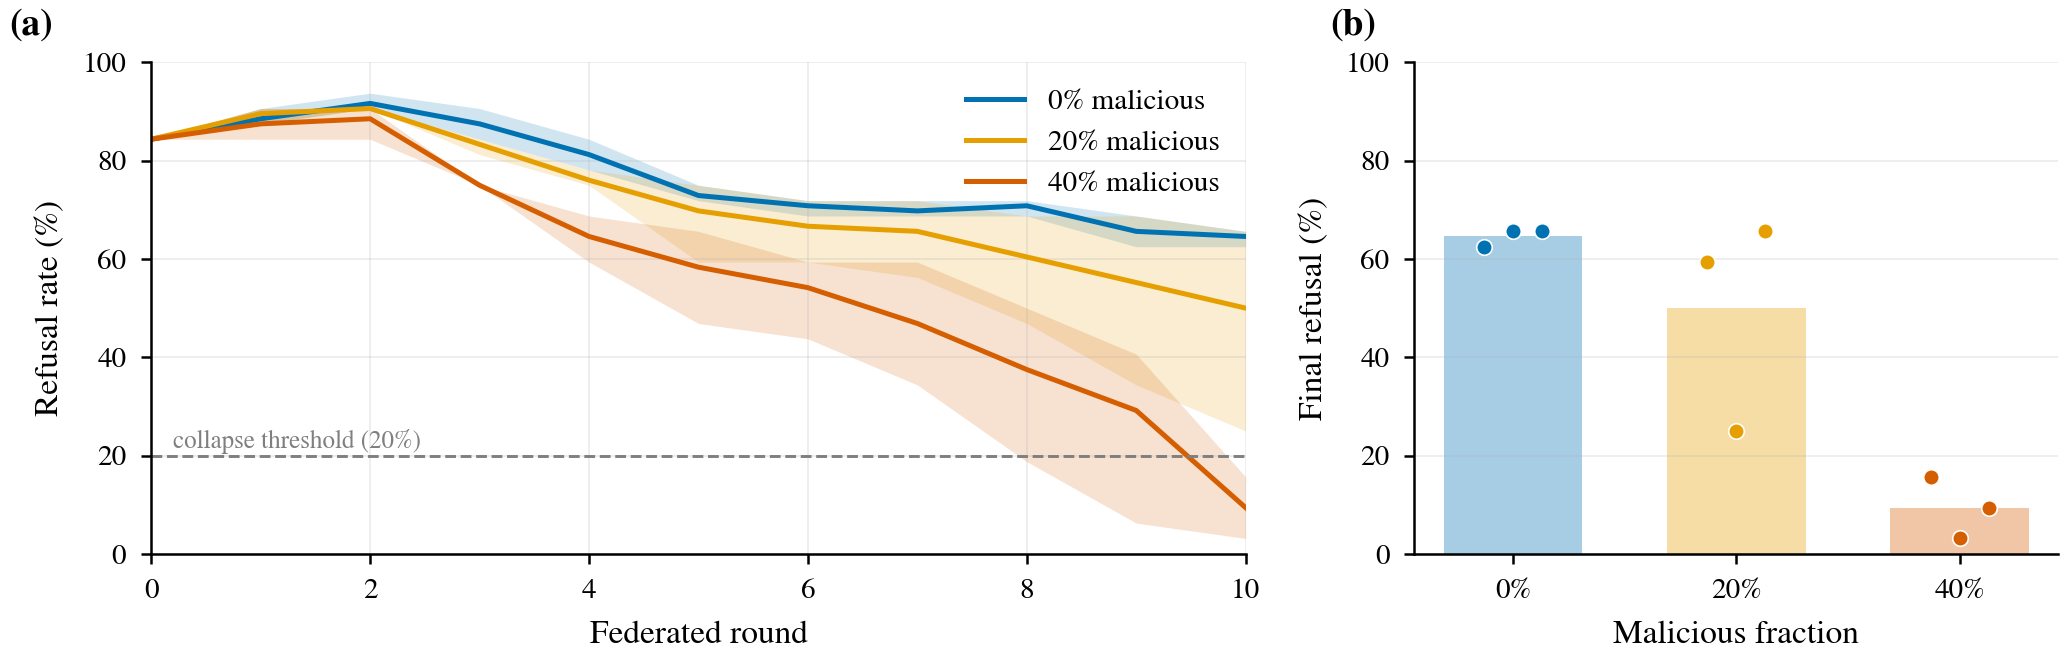


Figure: fig2_detection_window.png


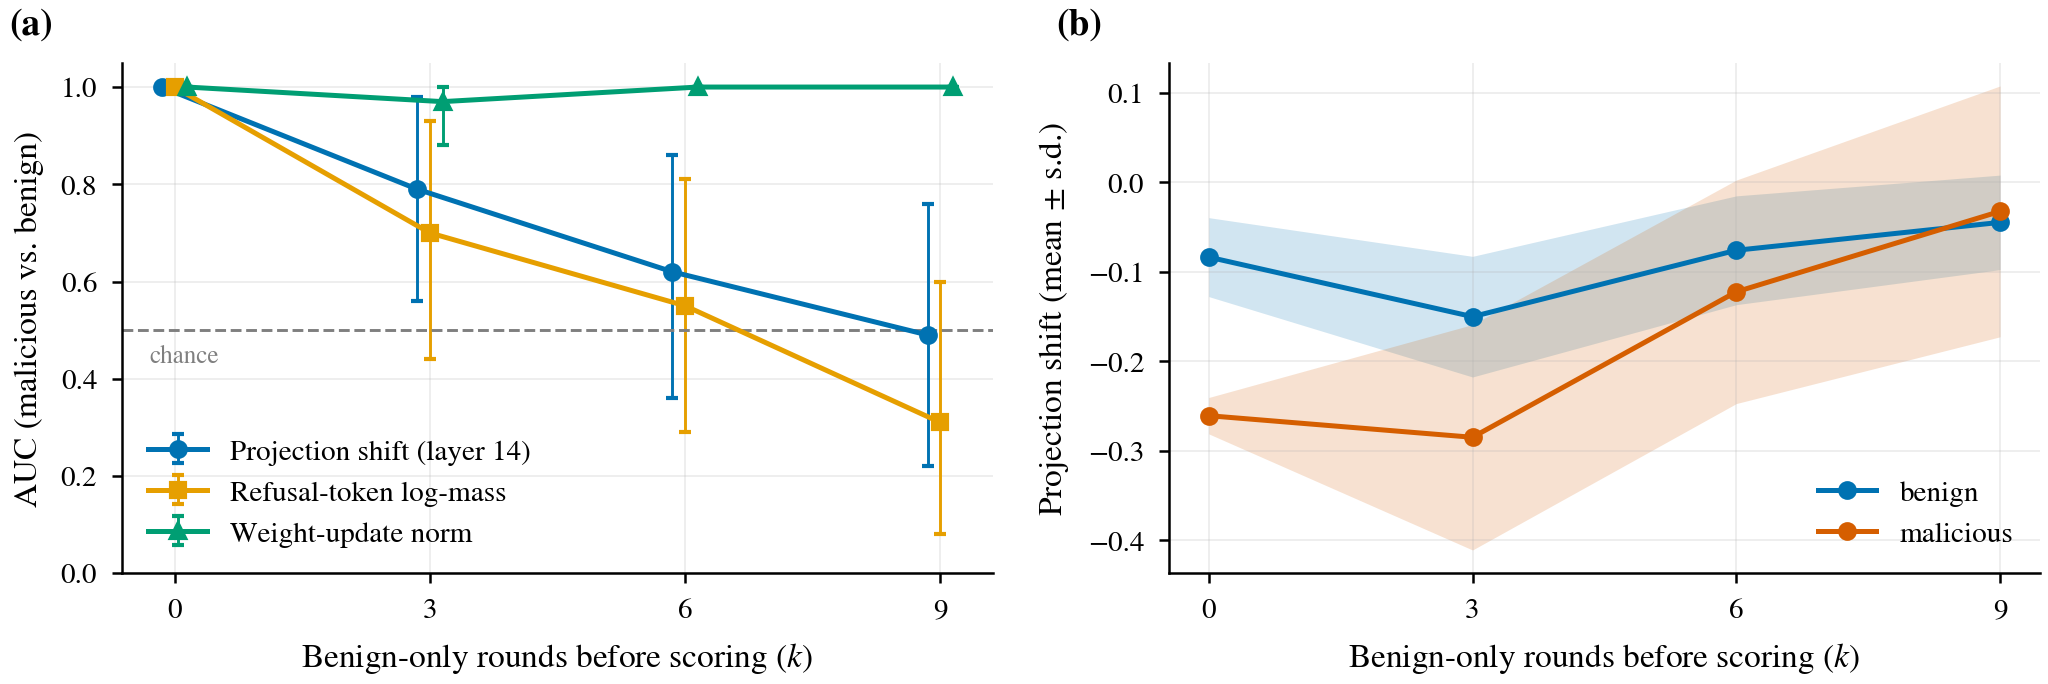


Figure: fig3_validation_adaptive_and_specificity.png


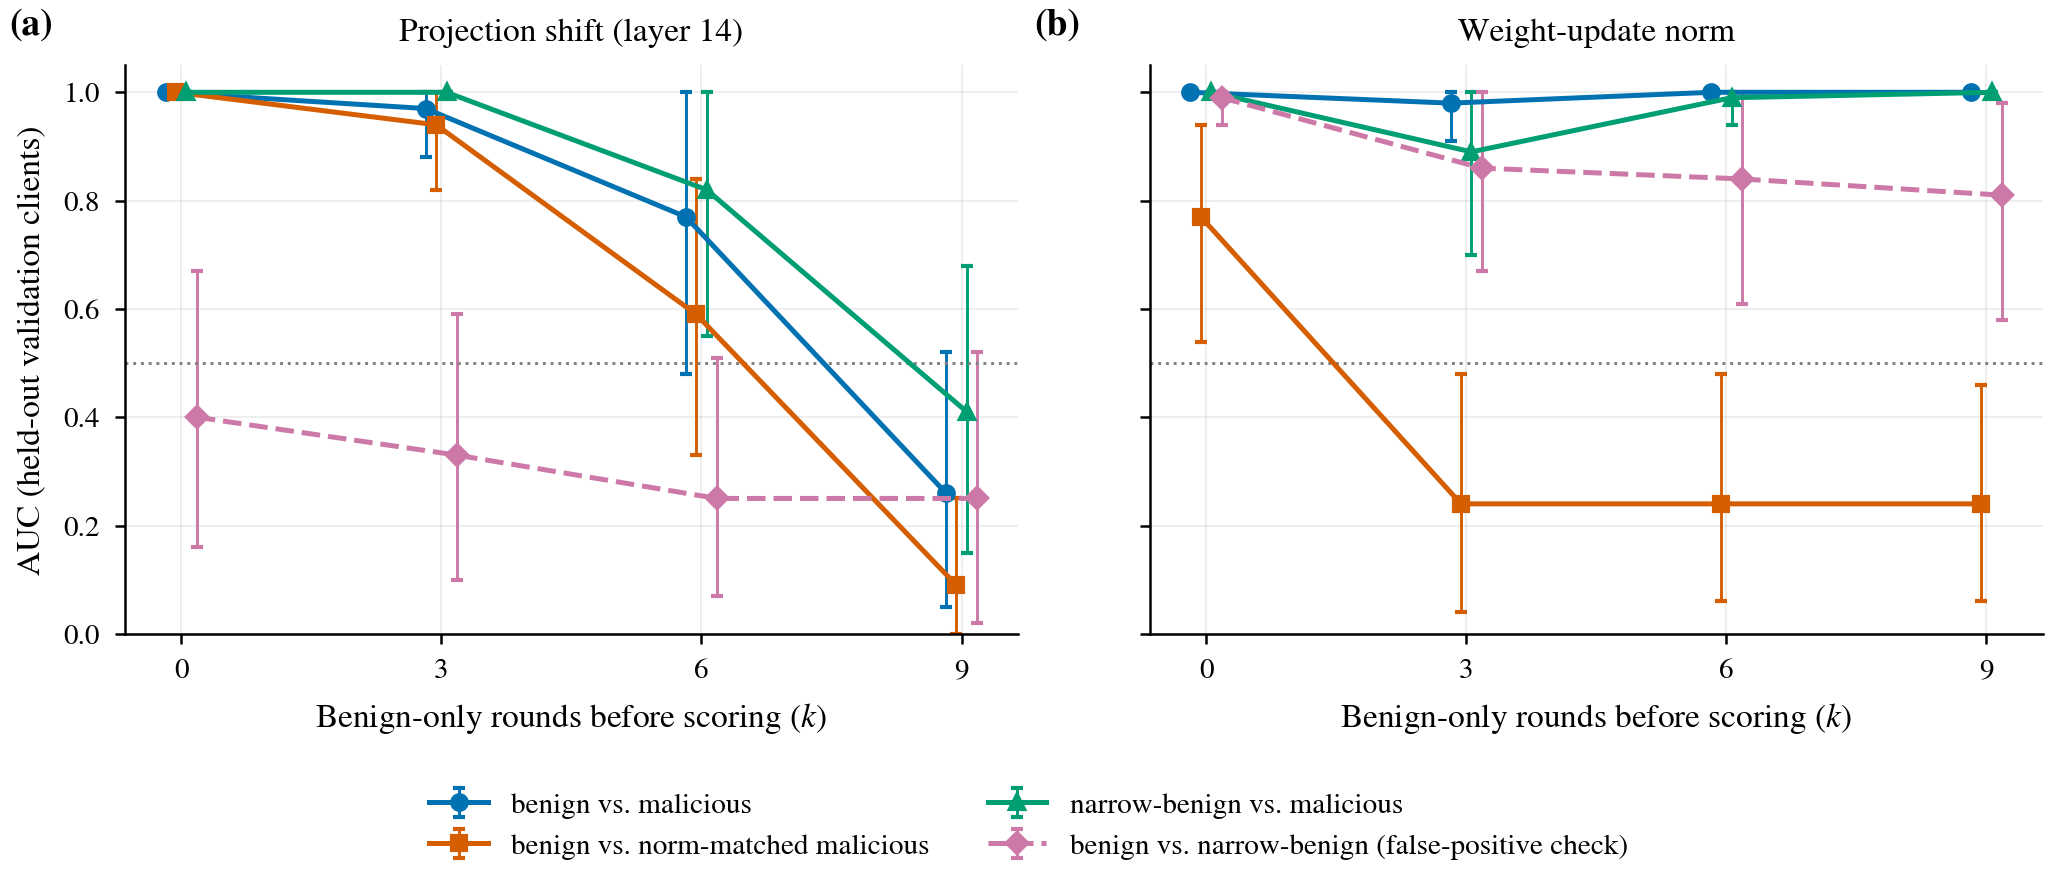


Figure: fig4_reference_scoring.png


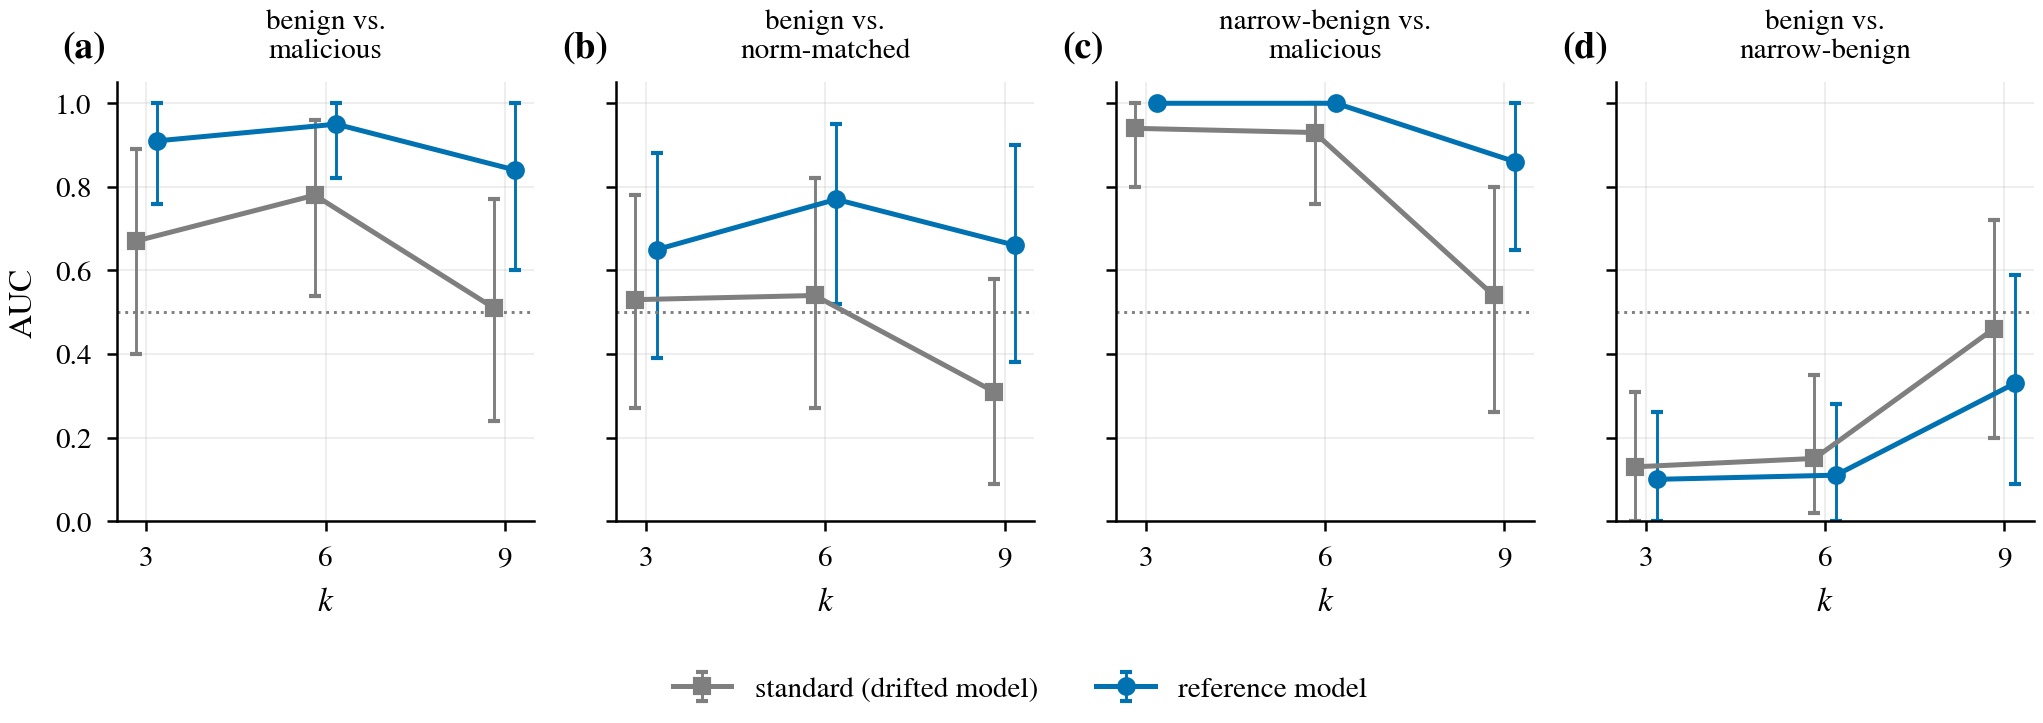


Figure: fig5_end_to_end_final_refusal.png


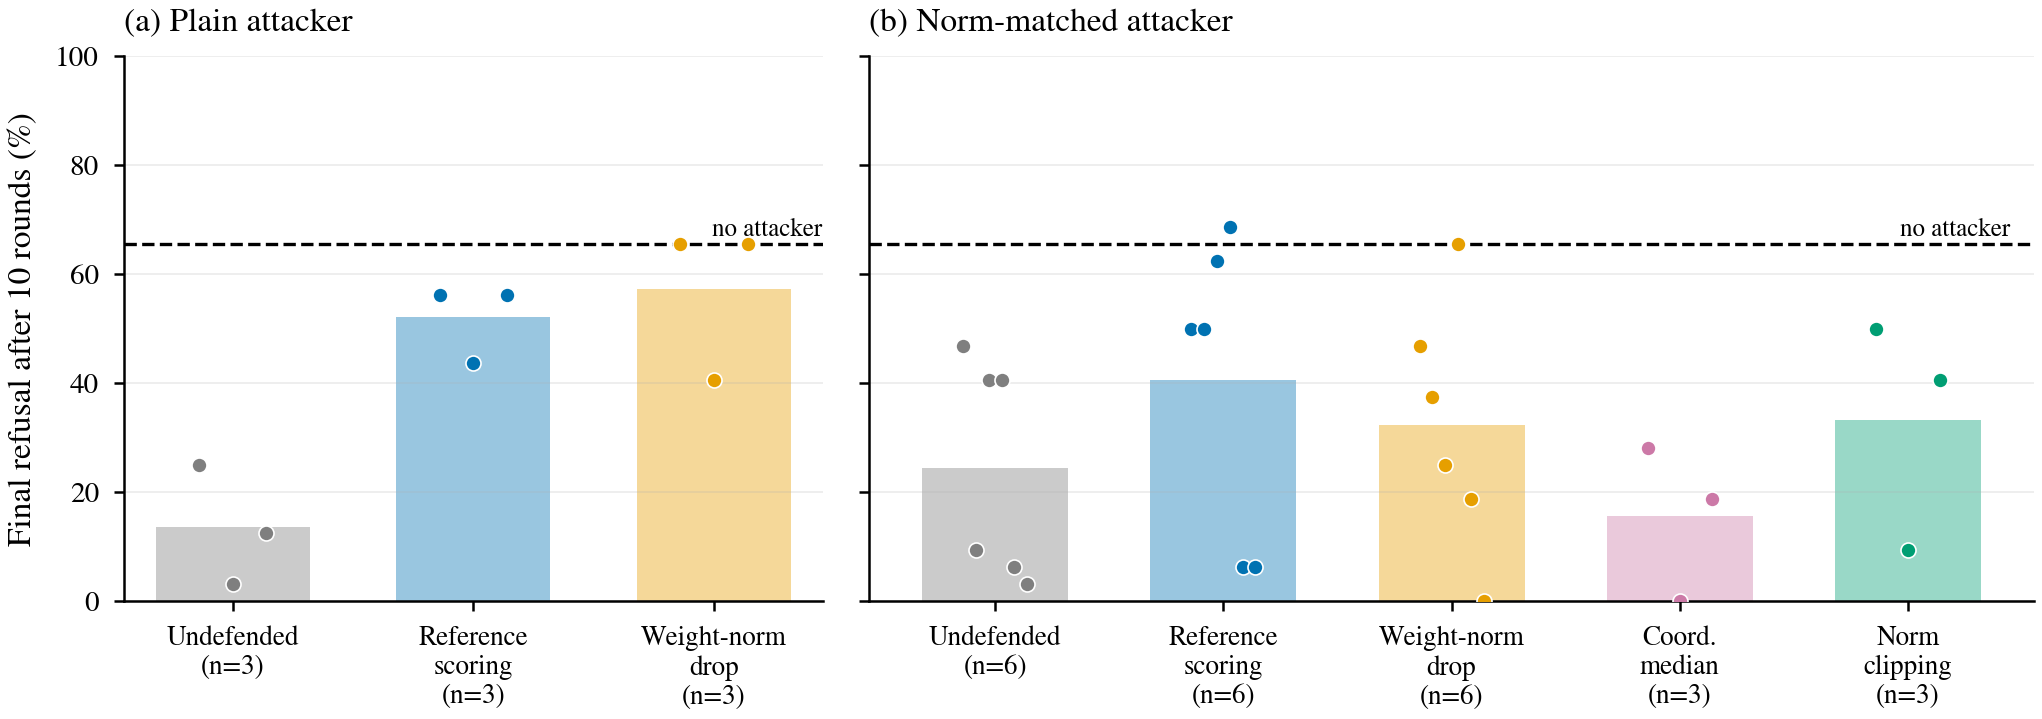


Figure: fig6_end_to_end_trajectories.png


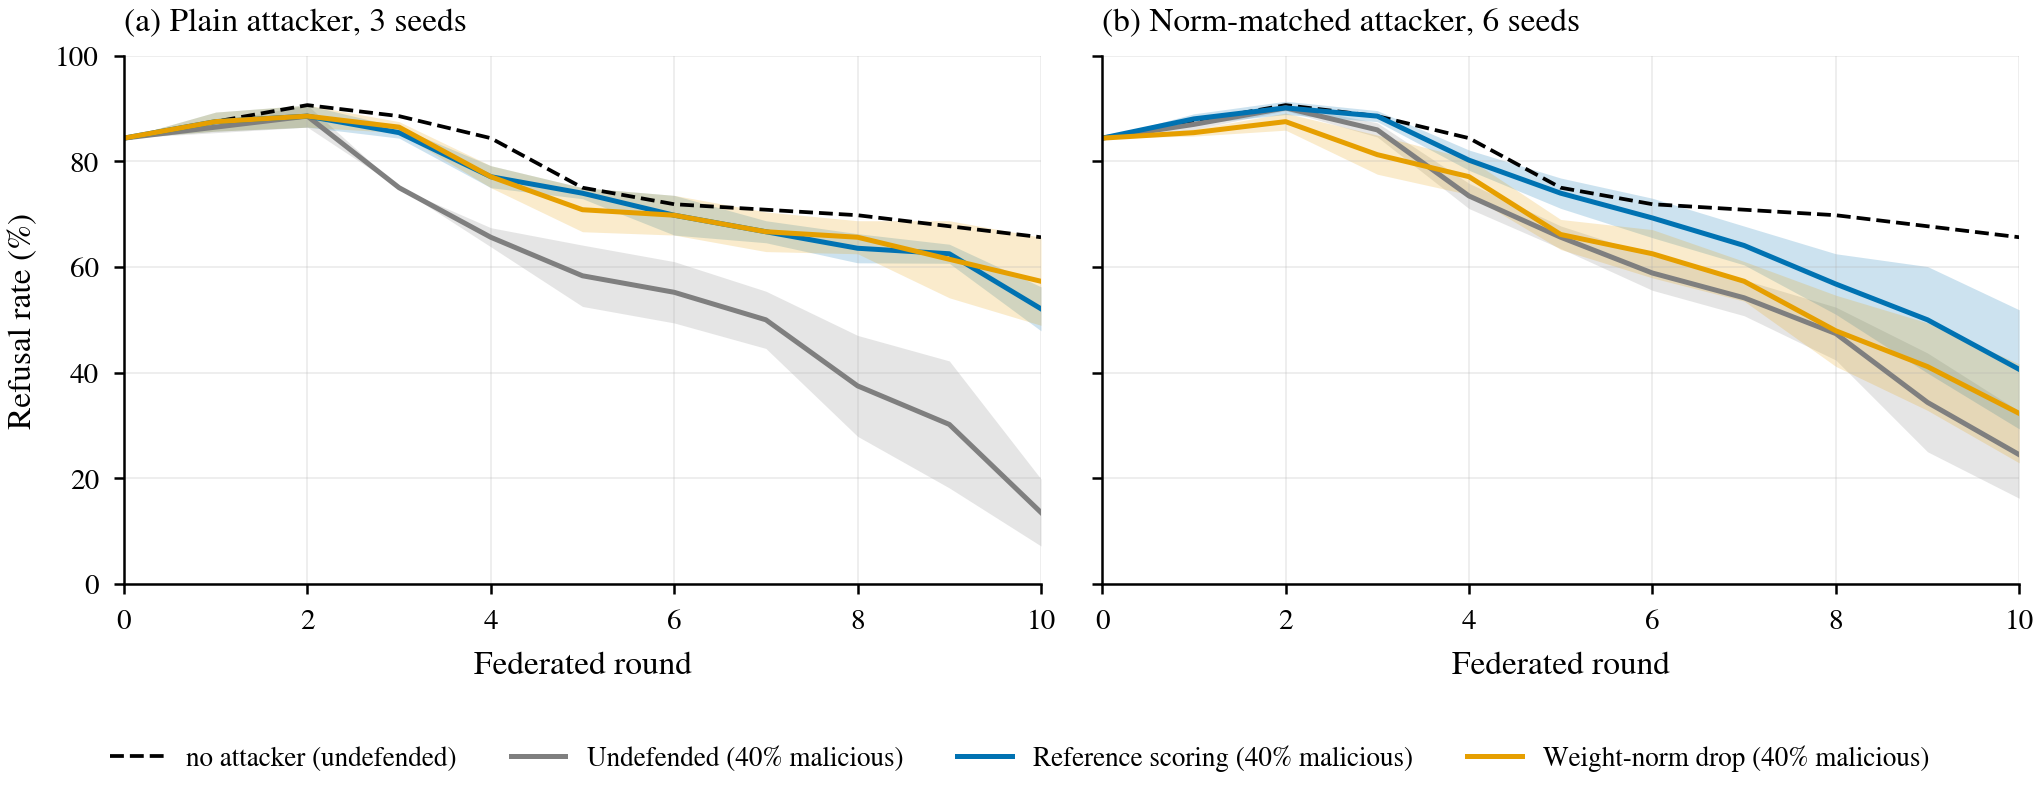


Figure: fig7_exposure_exploratory.png


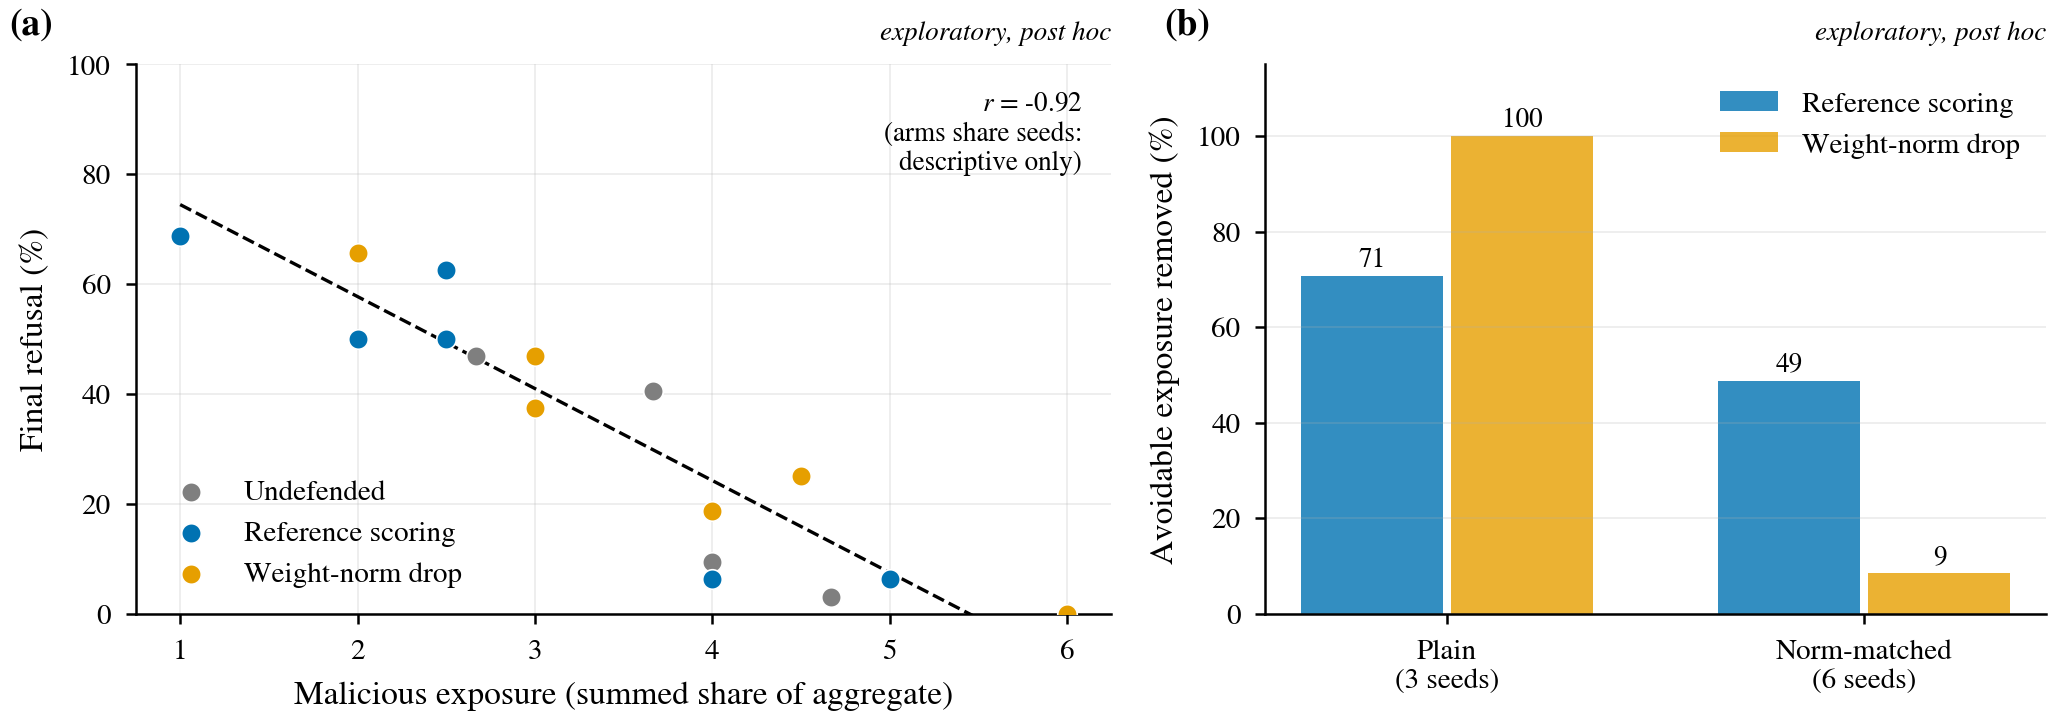


Figure: fig8_cost_no_attacker.png


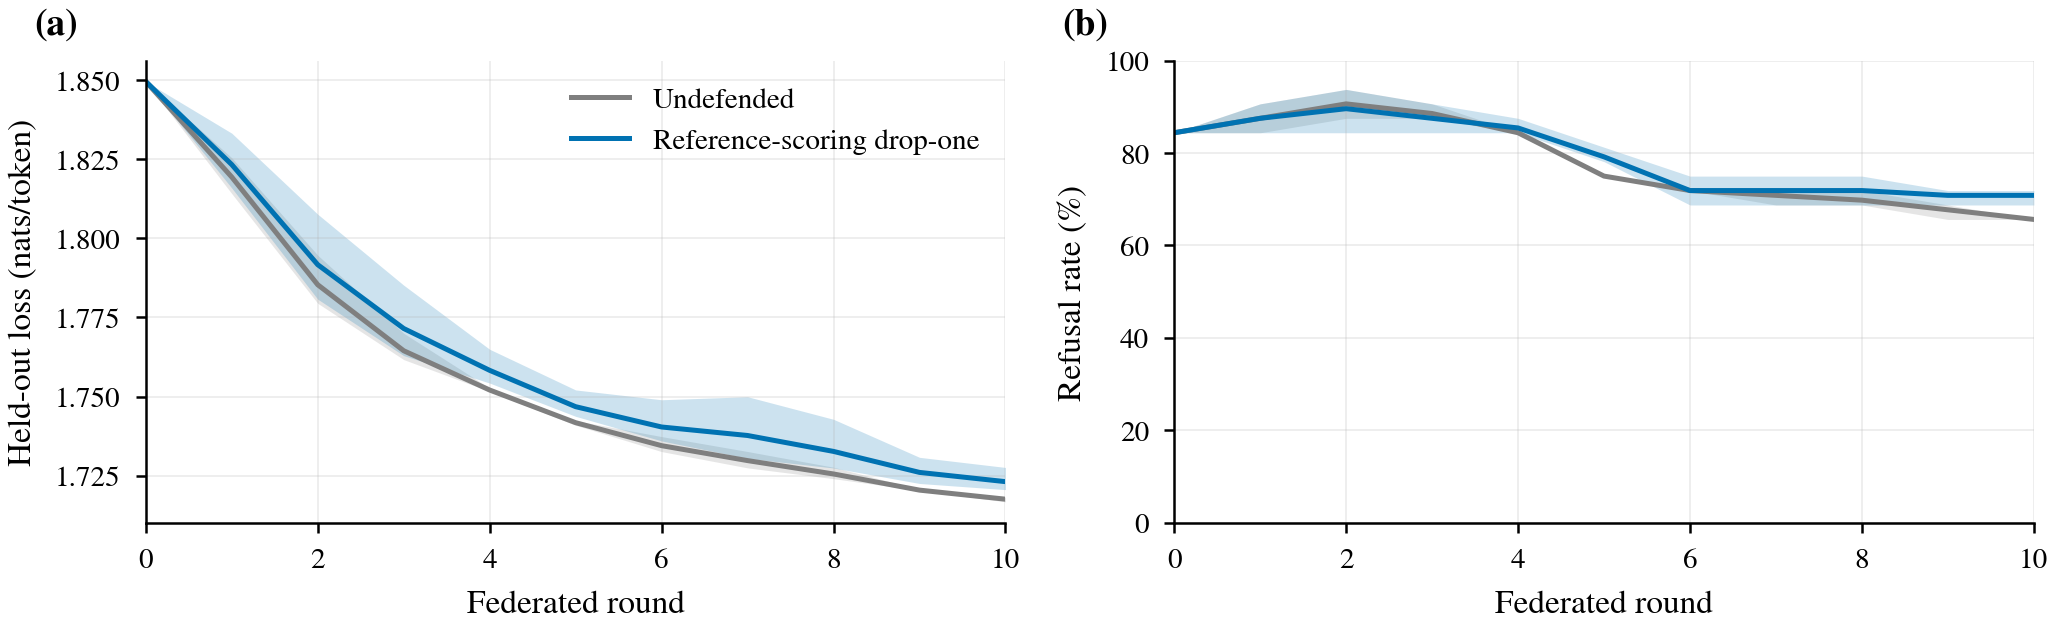

In [13]:
print("CELL 9: Figure 8 -- cost of the defense with no attacker (utility and refusal)")
def ut(d, key):
    T = [np.array(load_json(f"{UTIL}/{d}_plain_frac0.0_seed{s}_final.json")[key], float) for s in SEEDS3]
    return np.stack(T)
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.3))
for ax, (key, ylab, scale, lab) in zip(axes, [("util", "Held-out loss (nats/token)", 1.0, "(a)"), ("traj", "Refusal rate (%)", 100.0, "(b)")]):
    for d, name, c in [("fedavg", "Undefended", C["grey"]), ("refdrop1", "Reference-scoring drop-one", C["blue"])]:
        T = ut(d, key) * scale; x = np.arange(T.shape[1])
        ax.fill_between(x, T.min(0), T.max(0), color=c, alpha=0.2, lw=0); ax.plot(x, T.mean(0), color=c, label=name)
    ax.set_xlabel("Federated round"); ax.set_ylabel(ylab); ax.set_xlim(0, 10); panel(ax, lab)
    if key == "traj": ax.set_ylim(0, 100)
axes[0].legend(frameon=False, loc="upper right")
fig.tight_layout(); save(fig, "fig8_cost_no_attacker")

# Display all saved figures
import IPython.display as ipd
import glob

print("\n--- DISPLAYING ALL SAVED FIGURES ---")
for fpath in sorted(glob.glob(f"{FIG_DIR}/*.png")):
    print(f"\nFigure: {os.path.basename(fpath)}")
    ipd.display(ipd.Image(filename=fpath))